# LeetCode #80: Remove Duplicates from Sorted Array II

https://leetcode.com/problems/remove-duplicates-from-sorted-array-ii/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force (count, then rebuild)** | $O(n)$ | $O(n)$ |
| **Optimal: Two-Pointer Write Head ★** | $O(n)$ | $O(1)$ |

`n` is the length of the array. $O(n)$ time means one look per element: 30,000 elements, 30,000
looks. $O(1)$ space means the extra memory doesn't grow with the input; here it's a single counter.

**In place** means you rewrite the array you were given instead of building a new one. The first
`k` slots must end up holding the answer, and you return `k`; whatever sits after slot `k` is
ignored.

---

## Understanding the Methods

### Brute Force (count, then rebuild)
Walk the array, copy each value into a second list until you've copied it twice, then copy that
list back over `nums`. Easy to get right, but the second list can be as big as the input.

### Optimal: Two-Pointer Write Head ★
Keep a write position `k`: everything before it is the finished answer. Read each element once and
ask whether writing it would make three copies in a row. Because the array is sorted, copies sit
next to each other, so that happens exactly when the value two slots behind the write position,
`nums[k-2]`, is the same. If it isn't, write the element at `k` and move `k` on.

**Why this is better than Brute Force:** the same single pass, but the answer is built in the
input's own slots, so there's no second array.

**Constraints:**
* `1 <= nums.length <= 3 * 10^4`
* `-10^4 <= nums[i] <= 10^4`
* `nums` is sorted in non-decreasing order

## Explain Like I'm a Newbie

### What the question is actually asking

`nums` is sorted, so copies of a value sit side by side. Keep at most two copies of each value,
squeeze the survivors to the front of the same array, and return how many there are. Whatever is
left past that count doesn't matter.

```
in:   [1, 1, 1, 2, 2, 3]
out:  [1, 1, 2, 2, 3, _]    return 5   (the third 1 is gone)
```

### The one idea you need: check what you've written, not what you've read

Picture two fingers. The **read** finger walks every element once. The **write** finger `k` marks
the end of the finished answer: slots `0` to `k-1` are done.

For each element you read, ask one question: *if I write this, will the answer end in three of the
same value?* The answer so far ends in `nums[k-2]` and `nums[k-1]`. It's sorted, so if `nums[k-2]`
equals the new value, `nums[k-1]` (which sits between them) does too, and you'd be writing a third
copy. The whole test is `num != nums[k-2]`.

The tempting version compares with `nums[i-2]`, two behind the **read** finger. That looks at the
input, but the input is being overwritten as you go, so that slot may no longer hold what was
there.

### What that means in code

One index reads, one writes, and the writer never gets ahead of the reader, so nothing is
overwritten before it's been read. That's the **two-pointer write head** pattern.

1. While `k < 2`, accept anything: two copies are always allowed.
2. Otherwise accept `num` only if `num != nums[k-2]`.
3. Accepting means `nums[k] = num`, then `k += 1`.

### Mistakes people make the first time

1. **Comparing with `nums[i-2]`.** It passes the second sample, `[0,0,1,1,1,1,2,3,3]`, then returns
   4 on the first, `[1,1,1,2,2,3]`. The first 2 gets copied into slot 2, and when the second 2
   arrives it's compared with that copy and thrown away.
2. **Dropping the `k < 2` check.** In C#, Go and Rust, `nums[-2]` crashes. Python reads from the end
   of the array instead: both samples still pass, then `[1,2,2]` returns 1, because the last 2 makes
   the first 2 look like a third copy.
3. **Writing `k <= 2`.** When `k` is exactly 2 a third copy slips through: `[1,1,1]` comes back as 3.
4. **Returning the array instead of `k`.** The judge reads your `k` and checks only that many slots.

### Things worth knowing

The test generalises: to keep at most `m` copies, compare with `nums[k-m]`. With `m = 1` it's
LeetCode #26. It also changes the caller's array, which here is exactly what's asked.

## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The 30-second pitch

> **You:** "Sorted means copies are neighbours. I keep a write index `k`, and slots before `k` are the answer. For each number I read, I write it only if it's different from `nums[k-2]`, two slots back in what I've *written*: if that matches, the last two written are both this value and this one would be the third. One pass, O(n) time, O(1) extra space. What I'd watch is comparing against the write side and not the read side, because I'm overwriting the array as I read it."

---

### I slide the problem across the table

A sorted array, keep each value at most twice, do it in place, return the new length.

> **You:** "So I'm compacting in place: the first `k` slots hold the survivors in their original order, and I return `k`. Does anything after slot `k` matter?"

**"No, only the first `k` are checked."** Worth asking, because it means you don't have to clean anything up.

> **You:** "And sorted means non-decreasing, so equal values are always next to each other?"

**"Yes."** That's the clarifier I'm listening for, because the whole solution leans on it. In `[1,2,1,1]` the copies aren't neighbours and "two slots back" means nothing. Asking whether the array can be empty, when the constraints say at least one element, tells me you're reciting a list.

---

### Now tell me what's actually hard about it

"Two pointers" is a name, and on its own it tells me nothing. I want the difficulty first.

> **You:** "Counting copies is easy if I can see a whole run. The catch is that I'm overwriting the array while I read it. If I decide with the input, 'is this the same as the number two before it in the input?', I'm reading slots I may already have overwritten. In `[1,1,1,2,2,3]` the first 2 gets copied into slot 2. When I read the second 2 at index 4, `nums[2]` is now that copied 2, so it looks like a third copy and I throw away a 2 I needed."

That's exactly the bug I'd otherwise watch you write. And the fix falls out of it:

> **You:** "So I decide with what I've written. The answer so far, `nums[0..k-1]`, is sorted. The new number would be a third copy exactly when `nums[k-2]` equals it, because then `nums[k-1]`, sitting between them, equals it too."

---

### Before you touch the board, tell me the shape and the cost

> **You:** "One loop over the input and a write index `k` starting at 0. One `if`: accept when `k < 2` or `num != nums[k-2]`. Accepting writes `nums[k]` and bumps `k`. Return `k`."

Then the cost, with the reason:

> **You:** "Each element is read once and written at most once, and the test is one array lookup, so it's O(n), 30,000 iterations at the limit. Space is one integer. Writing into the same array is safe because `k` never passes the read position: I write at most one element per element I read, so slot `k` has always been read already."

That last sentence is the one most people can't produce, and it's the whole reason in place works.

---

### Now whiteboard it

```
k = 0
for num in nums:
```

> **You:** "I'm looping over the list while writing into it. That's fine here: every write lands at `k`, which is at or behind the element the loop is on."

If you don't say that, I'll ask "aren't you modifying the list while iterating over it?", and I'd rather you'd got there first.

```
    if k < 2 or num != nums[k - 2]:
```

> **You:** "`k < 2` first: the first two numbers always survive, and the short-circuit means I never index `nums[-2]`. In Python that wouldn't even crash; it'd read from the end of the list and quietly give wrong answers."

Here I might ask what happens with `k <= 2`. The answer I want: `[1,1,1]` comes back with three 1s, because when `k` is exactly 2 the third copy gets through without being checked.

```
        nums[k] = num
        k += 1
return k
```

Nothing to defend there, except that you return `k` and not the array.

---

### Walk me through it before you say you're done

> **You:** "`[1,1,1,2,2,3]`. The first two 1s go in on the `k < 2` branch, `k = 2`. The third 1: `nums[0]` is 1, the same, skip. The first 2: `nums[0]` is 1, different, write it at slot 2, `k = 3`. The second 2: `nums[1]` is 1, different, slot 3, `k = 4`. The 3: `nums[2]` is 2, different, slot 4, `k = 5`. Return 5, front is `[1,1,2,2,3]`."

> **You:** "A single element returns 1 through the `k < 2` branch. All the same, `[7,7,7,7]`, stops `k` at 2. All different writes every element onto itself. And sorted is what you said yes to at the start; it's why one comparison with `nums[k-2]` is enough."

---

### Then tell me what it leans on, before I ask

There's no faster version: you have to look at every element to know whether to keep it. So the beat becomes the assumption and how it generalises:

> **You:** "It leans on the input being sorted. Unsorted, `nums[k-2]` says nothing about how many copies I've kept, and I'd need a hash map of counts, which costs O(n) extra space. It generalises cleanly, though: to keep at most `m` copies, compare with `nums[k-m]`. With `m = 1` that's #26."

That's what I'm hoping for at the end: you know where the guarantee comes from, and you can bend it.

---

### What would worry me

Comparing with `nums[i-2]`, failing the first sample, and patching it with special cases instead of asking why it failed. A counter-and-flag version with three branches that's correct but that you can't explain. And not being able to say why writing into the array you're reading doesn't trample anything.

## Solutions

All four make one pass with a write index `k`, and keep a number only if it differs from the value two slots back in the part already written.

### C#

In [ ]:
public class Solution {
    public int RemoveDuplicates(int[] nums) {
        int k = 0; // write head: nums[0..k-1] is the finished answer so far

        // Writing into the array we're reading is safe: k never gets ahead of
        // the element being read, so nothing is overwritten before it's read
        foreach (int num in nums)
            // The first two always survive (k < 2 also keeps k - 2 in range).
            // After that, compare with what we WROTE two slots back, not what we
            // read: if nums[k-2] equals num, so does nums[k-1] (the array is
            // sorted), and writing num would make a third copy.
            if (k < 2 || num != nums[k - 2])
                nums[k++] = num;

        return k; // the judge checks only the first k slots
    }
}

### Python

`nums[-2]` doesn't raise in Python; it reads the second-to-last element. That's why the `k < 2` check matters even more here: without it the code runs and gives wrong answers instead of crashing.

In [ ]:
class Solution:
    def removeDuplicates(self, nums: list[int]) -> int:
        k = 0  # write head: nums[0..k-1] is the finished answer so far

        # Writes land at k, which is never past the element being read,
        # so changing nums while looping over it never tramples anything
        for num in nums:
            # The first two always survive. After that, compare with what we
            # WROTE two slots back, not what we read: if nums[k-2] equals num,
            # so does nums[k-1] (sorted), and num would be a third copy.
            # k < 2 must come first: nums[-2] would quietly read the END.
            if k < 2 or num != nums[k - 2]:
                nums[k] = num
                k += 1

        return k  # the judge checks only the first k slots

### Go

In [ ]:
func removeDuplicates(nums []int) int {
    k := 0 // write head: nums[0..k-1] is the finished answer so far

    // Writing into the slice we're reading is safe: k never gets ahead of
    // the element being read, so nothing is overwritten before it's read
    for _, num := range nums {
        // The first two always survive (k < 2 also keeps k-2 in range).
        // After that, compare with what we WROTE two slots back, not what we
        // read: if nums[k-2] equals num, so does nums[k-1] (sorted), and
        // writing num would make a third copy.
        if k < 2 || num != nums[k-2] {
            nums[k] = num
            k++
        }
    }
    return k // the judge checks only the first k slots
}

### Rust

The loop runs over indices rather than `nums.iter()`, because Rust won't let you hold a read borrow of `nums` while writing into it. `k` is `usize`, so `k - 2` would panic below zero; the `k < 2 ||` short-circuit means it's never evaluated there.

In [ ]:
impl Solution {
    pub fn remove_duplicates(nums: &mut Vec<i32>) -> i32 {
        let mut k = 0usize; // write head: nums[0..k] is the finished answer so far

        // Writing into the vector we're reading is safe: k never gets ahead
        // of i, so nothing is overwritten before it's read
        for i in 0..nums.len() {
            let num = nums[i];
            // The first two always survive (and k - 2 would underflow usize).
            // After that, compare with what we WROTE two slots back, not what we
            // read: if nums[k-2] equals num, so does nums[k-1] (sorted), and
            // writing num would make a third copy.
            if k < 2 || num != nums[k - 2] {
                nums[k] = num;
                k += 1;
            }
        }
        k as i32 // the judge checks only the first k slots
    }
}

## Example Scenarios

### 1. Common Case — One Value Appears Three Times
**Input:** `nums = [1, 1, 1, 2, 2, 3]`

The first two 1s go straight in. The third 1 finds a 1 two slots back in the answer, so it's
skipped; the two 2s and the 3 each find a different value there and are written. **Output:** `5`,
with `nums` starting `[1, 1, 2, 2, 3]`.

### 2. Slightly Complex — A Long Run in the Middle
**Input:** `nums = [0, 0, 1, 1, 1, 1, 2, 3, 3]`

The run of four 1s loses its last two. From then on every survivor is written two slots further
left than where it was read, which is why the test must look at the written side. **Output:** `7`,
with `nums` starting `[0, 0, 1, 1, 2, 3, 3]`.

### 3. Edge Case: Time Factor — Every Element the Same
**Input:** `nums` = $3 \times 10^4$ copies of `1`

The largest input allowed. The write position stops at 2 after the second element, and every later
element is read, compared and skipped: one look each, $3 \times 10^4$ in all, so $O(n)$ even when
almost nothing is kept. **Output:** `2`

### 4. Edge Case: Space Factor — Nothing to Remove
**Input:** `nums = [1, 2, 3, ..., 10000]` (10,000 different values)

Every element is kept, so the answer is as long as it can be and every element is written (onto
itself). The answer still lives in the input's own slots: the only extra memory is `k`, $O(1)$.
**Output:** `10000`

### 5. Almost-Impossible but Plausible — Three Copies of the Smallest Value
**Input:** `nums = [-10000, -10000, -10000]`

The smallest values allowed, and the shortest array where anything gets removed. The first two
enter through the `k < 2` check without being compared; the third meets `nums[0] = -10000` and is
dropped. **Output:** `2`

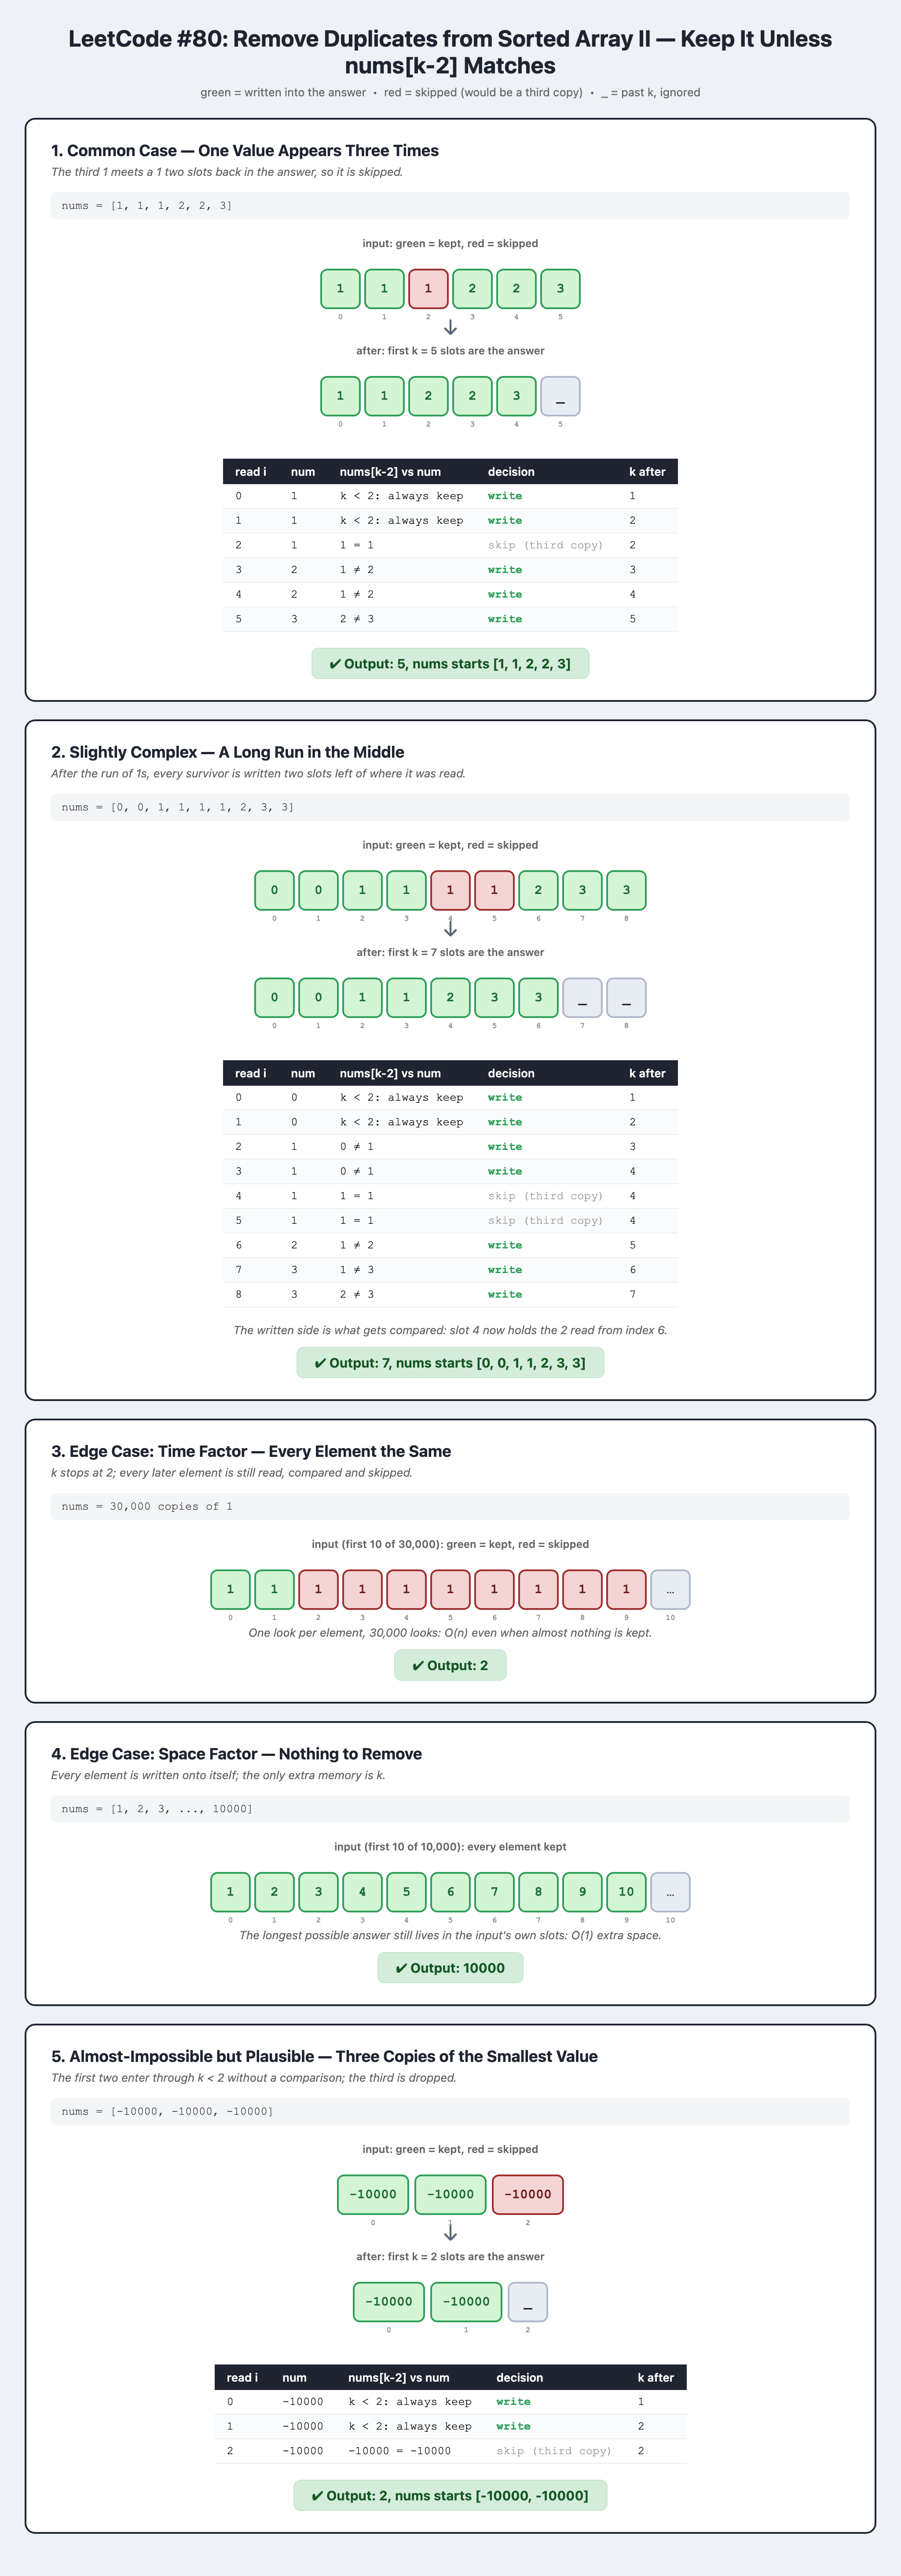

## Watch It Run

*Watch the third 1: two slots back in the answer is another 1, so it's skipped, and then the first 2 is written into the slot that 1 was read from.*

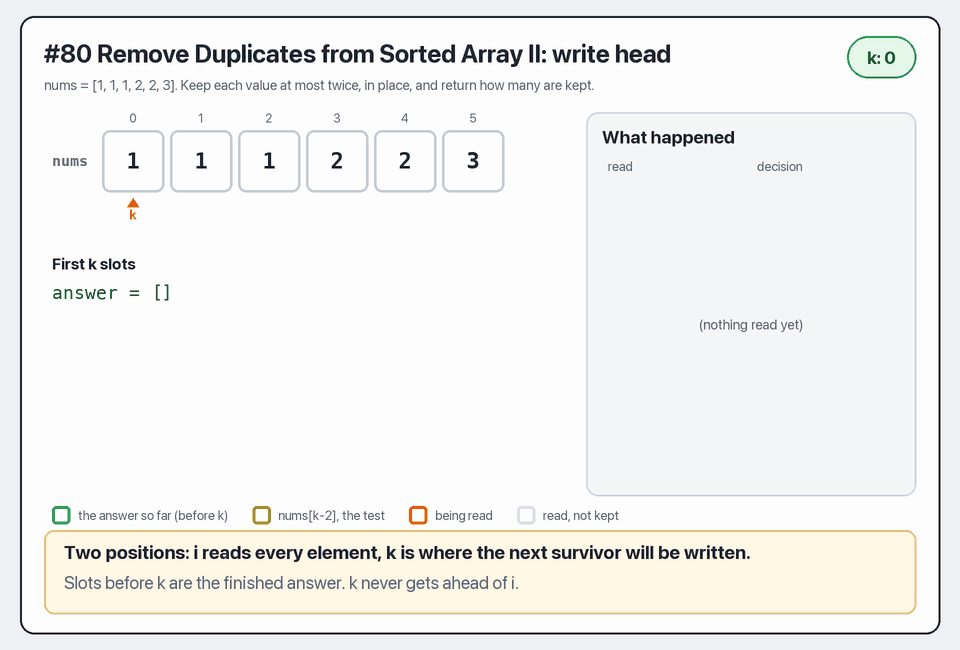

**[Step through it yourself: play, pause, scrub and step through this walkthrough, plus a harder example](https://sanjay-bhat.github.io/ProgrammingConcepts/walkthroughs/0080.html)**